# CNN–LSTM Battery SOH Baseline (adapted Ma et al., 2025)

**Paper:** Ma et al., *Sustainability* 17, 4014 (2025), DOI: 10.3390/su17094014.  
**Important:** This is an **adapted architecture reproduction**, not an exact recreation of the paper’s preprocessing, three selected H1–H3 features, or experimental results. This notebook uses our five charging features, a parallel multiscale CNN (kernels 3, 5, 9), two-layer LSTM (256 units), dropout, and a linear SOH regression head. No physics penalty is applied.  

- `train_final_filtered.csv` is used for training; original `validation.csv` and `test.csv` remain unchanged.
- No sequence is permitted to cross a gap in `cycle_ordinal` or a battery boundary.
- All feature scaling is fit on training data only.
- For strict parity with older baseline notebooks, use the same sequence length and preprocessing policy, and make sure all models evaluate identical target samples.


In [ ]:
%pip install -q numpy pandas torch matplotlib scikit-learn

In [1]:
from pathlib import Path
import json, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
OUTPUT_DIR = DATA_DIR / "cnn_lstm_paper_baseline"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
SEQ_LEN=12
EPOCHS=100
BATCH_SIZE=128
LR=1e-3
PATIENCE=15
SEEDS=[42,123,2026]
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
for name in ['train_final_filtered.csv','validation.csv','test.csv']:
    assert (DATA_DIR/name).exists(), f'Missing {DATA_DIR/name}'


Device: cuda


In [2]:
train=pd.read_csv(DATA_DIR/'train_final_filtered.csv')
val=pd.read_csv(DATA_DIR/'validation.csv')
test=pd.read_csv(DATA_DIR/'test.csv')
for frame, name in [(train,'train'),(val,'validation'),(test,'test')]:
    missing=set(FEATURES+['battery','cycle_ordinal',TARGET])-set(frame.columns)
    if missing: raise ValueError(f'{name} missing columns: {missing}')
    if frame[FEATURES+[TARGET]].isna().any().any(): raise ValueError(f'{name} contains missing inputs or targets')
    if frame.duplicated(['battery','cycle_ordinal']).any(): raise ValueError(f'{name} has duplicate battery/cycle IDs')
    print(name, frame.shape, sorted(frame.battery.unique()))
assert set(train.battery).isdisjoint(val.battery)
assert set(train.battery).isdisjoint(test.battery)
assert set(val.battery).isdisjoint(test.battery)

scaler=StandardScaler().fit(train[FEATURES].to_numpy(dtype=np.float64))
with open(OUTPUT_DIR/'scaler.json','w') as f:
    json.dump({'features':FEATURES,'mean':scaler.mean_.tolist(),'scale':scaler.scale_.tolist()},f,indent=2)


train (7690, 13) ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation (1743, 13) ['CX2_36']
test (1477, 13) ['CX2_38']


In [3]:
def make_windows(frame, seq_len=SEQ_LEN):
    xs,ys,meta=[],[],[]
    for battery, part in frame.groupby('battery'):
        part=part.sort_values('cycle_ordinal').reset_index(drop=True)
        cycles=part.cycle_ordinal.to_numpy()
        values=scaler.transform(part[FEATURES].to_numpy(dtype=np.float64)).astype(np.float32)
        targets=part[TARGET].to_numpy(dtype=np.float32)
        # Divide into maximal uninterrupted runs of consecutive ordinal IDs
        boundaries=np.r_[0, np.flatnonzero(np.diff(cycles)!=1)+1, len(part)]
        for a,z in zip(boundaries[:-1],boundaries[1:]):
            for end in range(a+seq_len-1,z):
                start=end-seq_len+1
                xs.append(values[start:end+1]); ys.append(targets[end])
                meta.append({'battery':battery,'cycle_ordinal':int(cycles[end]),'soh':float(targets[end])})
    if not xs: raise ValueError('No full contiguous windows. Reduce SEQ_LEN or inspect cycle ordinals.')
    return np.stack(xs),np.array(ys,dtype=np.float32),pd.DataFrame(meta)

Xtr,ytr,mtr=make_windows(train)
Xva,yva,mva=make_windows(val)
Xte,yte,mte=make_windows(test)
print('Window counts:',len(ytr),len(yva),len(yte),'Shape:',Xtr.shape)
print('Excluded from evaluation due to warm-up or gaps:',len(test)-len(yte))


Window counts: 3869 918 752 Shape: (3869, 12, 5)
Excluded from evaluation due to warm-up or gaps: 725


## Adapted architecture
Three **parallel same-padded Conv1d branches** with temporal kernels 3, 5, 9; concatenation → 2-layer LSTM (hidden 256) → dropout → linear regression head. Parallel filters are an engineering choice for the five-feature cycle windows; the paper's diagram and convolution dimensional notation do not establish this exact topology.

In [4]:
class PaperInspiredCNNLSTM(nn.Module):
    def __init__(self,n_features=5,branch_channels=32,hidden=256,dropout=0.2):
        super().__init__()
        self.branches=nn.ModuleList([
            nn.Sequential(nn.Conv1d(n_features,branch_channels,kernel_size=k,padding=k//2),nn.ReLU())
            for k in (3,5,9)
        ])
        self.lstm=nn.LSTM(input_size=branch_channels*3,hidden_size=hidden,
                          num_layers=2,dropout=dropout,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self,x): # (batch,cycles,features)
        z=x.transpose(1,2)
        z=torch.cat([branch(z) for branch in self.branches],dim=1)
        z=z.transpose(1,2)
        z,_=self.lstm(z)
        return self.head(z[:,-1,:]).squeeze(-1)

model=PaperInspiredCNNLSTM().to(DEVICE)
print('Parameters:',sum(p.numel() for p in model.parameters()))
print('Example output:',model(torch.from_numpy(Xtr[:2]).to(DEVICE)).shape)


Parameters: 891905
Example output: torch.Size([2])


In [5]:
def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'mae_pp':float(mean_absolute_error(y,p)*100),
            'rmse_pp':float(np.sqrt(mean_squared_error(y,p))*100),
            'mbe_pp':float(np.mean(p-y)*100),
            'mape_percent':float(np.mean(np.abs((p-y)/np.maximum(np.abs(y),1e-8)))*100),
            'r2':float(r2_score(y,p))}

def predict(model,X,batch=512):
    model.eval(); out=[]
    loader=DataLoader(torch.from_numpy(X),batch_size=batch)
    with torch.no_grad():
        for xx in loader: out.append(model(xx.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def train_one(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    net=PaperInspiredCNNLSTM(n_features=len(FEATURES)).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    loss_fn=nn.MSELoss()
    loader=DataLoader(TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr)),
                      batch_size=BATCH_SIZE,shuffle=True)
    best=float('inf');best_state=None;bad=0;history=[];start=time.time()
    for epoch in range(1,EPOCHS+1):
        net.train();total=0.;count=0
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=loss_fn(net(xb),yb)
            loss.backward();torch.nn.utils.clip_grad_norm_(net.parameters(),1.0)
            opt.step();total+=loss.item()*len(yb);count+=len(yb)
        val_pred=predict(net,Xva)
        val_mse=float(np.mean((val_pred-yva)**2))
        history.append({'epoch':epoch,'train_mse':total/count,'val_mse':val_mse})
        if val_mse<best-1e-8:
            best=val_mse;best_state=copy.deepcopy(net.state_dict());bad=0
        else:bad+=1
        if epoch==1 or epoch%10==0 or bad>=PATIENCE:
            print(f'Seed {seed} epoch {epoch:3d} train MSE {total/count:.6f} val MSE {val_mse:.6f}')
        if bad>=PATIENCE:break
    net.load_state_dict(best_state)
    torch.save({'model_state':net.state_dict(),'features':FEATURES,'seq_len':SEQ_LEN,
                'seed':seed,'architecture':'adapted parallel CNN LSTM'},OUTPUT_DIR/f'cnn_lstm_seed{seed}.pt')
    pd.DataFrame(history).to_csv(OUTPUT_DIR/f'history_seed{seed}.csv',index=False)
    rows=[]
    for split,X,y,meta in [('train',Xtr,ytr,mtr),('validation',Xva,yva,mva),('test',Xte,yte,mte)]:
        pred=predict(net,X);out=meta.copy();out['prediction']=pred;out['error']=pred-y
        out.to_csv(OUTPUT_DIR/f'predictions_{split}_seed{seed}.csv',index=False)
        rows.append({'seed':seed,'split':split,'epochs':len(history),
                     'training_seconds':round(time.time()-start,2),**metrics(y,pred)})
    return rows,history


In [6]:
all_rows=[]; histories={}
for seed in SEEDS:
    rows,hist=train_one(seed)
    all_rows.extend(rows);histories[seed]=hist
results=pd.DataFrame(all_rows)
results.to_csv(OUTPUT_DIR/'metrics_all_runs.csv',index=False)
display(results.round(4))
summary=results.groupby('split')[['mae_pp','rmse_pp','mbe_pp','mape_percent','r2']].agg(['mean','std'])
summary.to_csv(OUTPUT_DIR/'metrics_summary.csv')
display(summary.round(4))


Seed 42 epoch   1 train MSE 0.071891 val MSE 0.001718
Seed 42 epoch  10 train MSE 0.000851 val MSE 0.000216
Seed 42 epoch  20 train MSE 0.000784 val MSE 0.001053
Seed 42 epoch  30 train MSE 0.000663 val MSE 0.000115
Seed 42 epoch  40 train MSE 0.000658 val MSE 0.000091
Seed 42 epoch  41 train MSE 0.000612 val MSE 0.000269
Seed 123 epoch   1 train MSE 0.069976 val MSE 0.002118
Seed 123 epoch  10 train MSE 0.001035 val MSE 0.000570
Seed 123 epoch  20 train MSE 0.000827 val MSE 0.000227
Seed 123 epoch  23 train MSE 0.000790 val MSE 0.000279
Seed 2026 epoch   1 train MSE 0.058647 val MSE 0.001974
Seed 2026 epoch  10 train MSE 0.000812 val MSE 0.001505
Seed 2026 epoch  20 train MSE 0.000665 val MSE 0.000287
Seed 2026 epoch  29 train MSE 0.000642 val MSE 0.000140


,seed,split,epochs,training_seconds,mae_pp,rmse_pp,mbe_pp,mape_percent,r2
0,42,train,41,14.10,0.9228,1.1220,-0.8919,1.1985,0.9889
1,42,validation,41,14.13,0.7144,0.9147,-0.1765,1.0043,0.9943
2,42,test,41,14.16,0.8607,1.0229,0.7760,1.1268,0.9933
3,123,train,23,8.15,0.6878,0.8805,0.1465,0.8913,0.9932
4,123,validation,23,8.18,0.9586,1.2235,0.6811,1.3469,0.9899
5,123,test,23,8.20,1.3557,1.5804,1.3151,1.7010,0.9840
6,2026,train,29,20.08,0.9878,1.3636,-0.8968,1.3939,0.9837
7,2026,validation,29,20.15,0.8149,1.0495,-0.0549,1.1657,0.9925
8,2026,test,29,20.20,0.9241,1.0657,0.8417,1.1651,0.9927


mae_pp         rmse_pp          mbe_pp         mape_percent  \
              mean     std    mean     std    mean     std         mean   
split                                                                     
test        1.0468  0.2694  1.2230  0.3103  0.9776  0.2941       1.3310   
train       0.8661  0.1578  1.1220  0.2415 -0.5474  0.6009       1.1612   
validation  0.8293  0.1227  1.0626  0.1549  0.1499  0.4640       1.1723   

                        r2          
               std    mean     std  
split                               
test        0.3210  0.9900  0.0052  
train       0.2534  0.9886  0.0048  
validation  0.1714  0.9922  0.0023

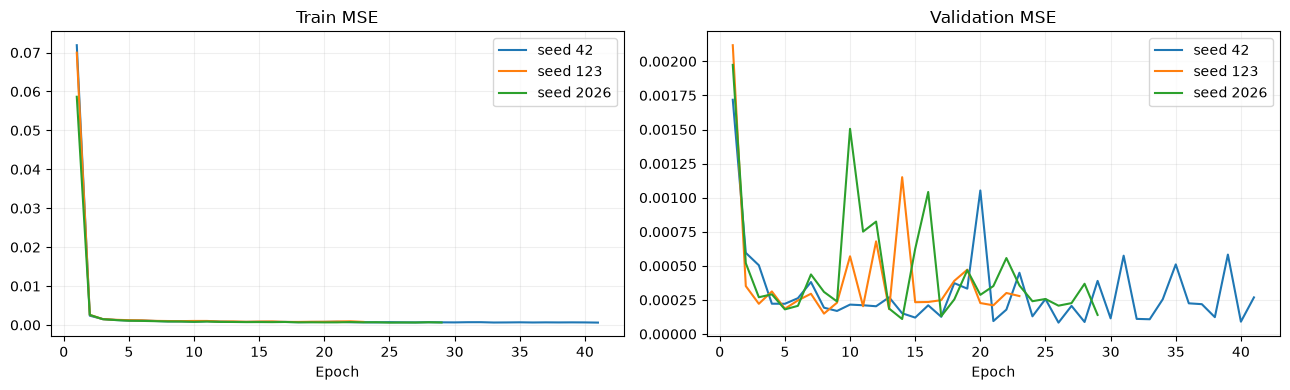

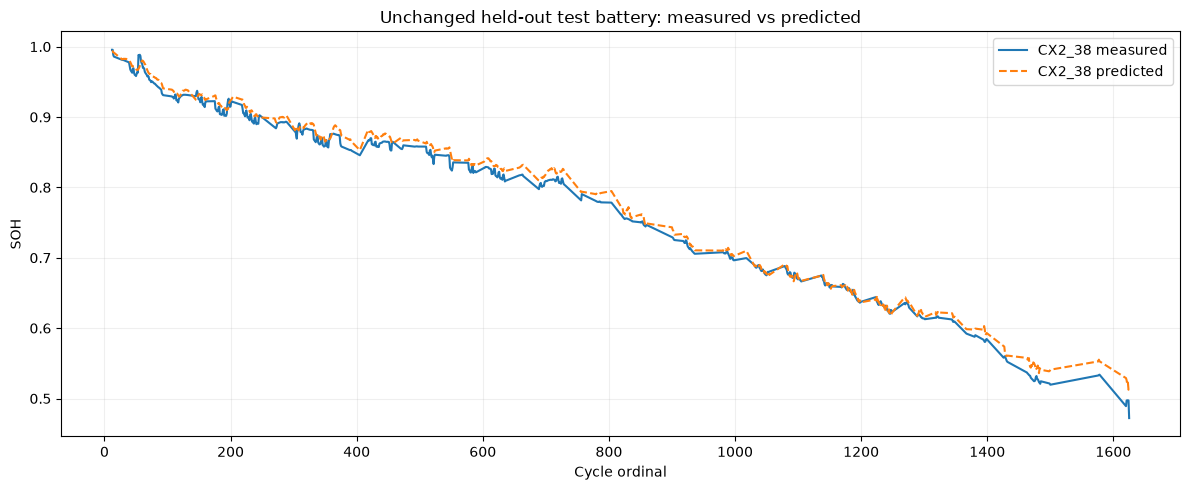

Saved to: C:\Projects\Battery_Soh\pre processed ready to use data\cnn_lstm_paper_baseline


In [7]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for seed,h in histories.items():
    d=pd.DataFrame(h)
    axs[0].plot(d.epoch,d.train_mse,label=f'seed {seed}')
    axs[1].plot(d.epoch,d.val_mse,label=f'seed {seed}')
for ax,title in zip(axs,['Train MSE','Validation MSE']):
    ax.set_title(title);ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'learning_curves.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(12,5))
res=pd.read_csv(OUTPUT_DIR/'predictions_test_seed42.csv')
for battery,g in res.groupby('battery'):
    g=g.sort_values('cycle_ordinal')
    ax.plot(g.cycle_ordinal,g.soh,label=f'{battery} measured')
    ax.plot(g.cycle_ordinal,g.prediction,'--',label=f'{battery} predicted')
ax.set(xlabel='Cycle ordinal',ylabel='SOH',title='Unchanged held-out test battery: measured vs predicted')
ax.grid(alpha=.2);ax.legend();plt.tight_layout()
plt.savefig(OUTPUT_DIR/'test_predictions.png',dpi=160);plt.show()
print('Saved to:',OUTPUT_DIR)


## Interpretation and reproduction limits
- **MAE/RMSE/MBE are percentage points** (`100 ×` fractional SOH error); MAPE is relative percent.
- Do not compare our numerical result directly to the paper's reported 0.339% (CS2_33) and 0.239% (CS2_35) RMSE as though protocols matched.
- The paper selected H1, H2 and H3 from raw charge/discharge signals, while this notebook uses 5 pre-extracted features and a different cell-disjoint split.
- The `train_final_filtered.csv` observations were removed by a statistical threshold; this does **not** establish that they were erroneous.
- This notebook predicts the **current cycle's** SOH from features observed through that cycle; it is **SOH estimation**, not multi-cycle future forecasting.
- Since windowing skips gaps, each evaluation covers a subset of the original CSV. Use exactly matched windows when comparing to competing architectures.
